In [ ]:
# Initialisation

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import umap

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

SEED = 0
SAMPLES_PER_CLASS = 500
CLASS_IDS = list(range(10))

np.random.seed(SEED)
torch.manual_seed(SEED)

/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


100%|███████████████████████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:02<00:00, 4.25MB/s]
100%|████████████████████████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 285kB/s]
100%|███████████████████████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:00<00:00, 2.31MB/s]
100%|███████████████████████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 4.18MB/s]


MNIST: (5000, 784)


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


MNIST embedding: (5000, 2)


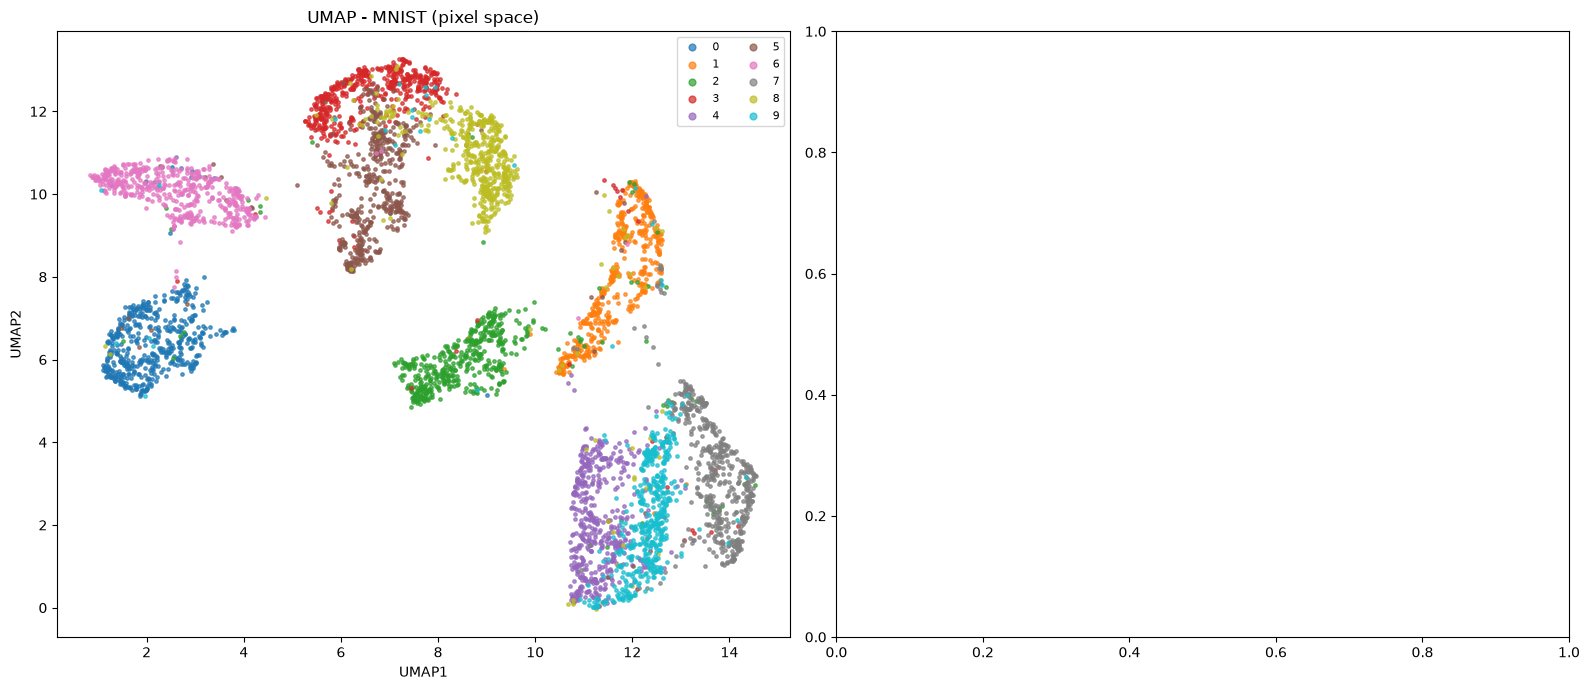

In [ ]:
# Experiment 0

mnist = datasets.MNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
"""
imagenet_transform = transforms.Compose([
  transforms.Resize((64,64)),
  transforms.ToTensor()
])
imagenet = datasets.ImageNet(root="/path/to/imagenet", split="train", transform=imagenet_transform)
"""

def balanced_subset(dataset, class_ids, n_per_class=500, seed=0):
  rng = np.random.default_rng(seed)
  targets = np.asarray(dataset.targets)
  selected_indices = []
  for class_id in class_ids:
    candidates = np.flatnonzero(targets == class_id)
    if len(candidates) < n_per_class:
      raise ValueError(f"Class {class_id} has only {len(candidates)} images.")
    indices = rng.choice(candidates, size=n_per_class, replace=False)
    selected_indices.extend(indices.tolist())
  rng.shuffle(selected_indices)
  return Subset(dataset, selected_indices)

mnist_subset = balanced_subset(mnist, CLASS_IDS, SAMPLES_PER_CLASS, SEED)

# imagenet_subset = balanced_subset(imagenet, CLASS_IDS, SAMPLES_PER_CLASS, SEED)

def extract_pixels(dataset, batch_size=128):
  loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
  features=[]
  labels=[]
  for images, targets in loader:
    flattened = images.flatten(start_dim=1)
    features.append(flattened.numpy())
    labels.append(targets.numpy())
  X = np.concatenate(features, axis=0).astype(np.float32)
  y = np.concatenate(labels, axis=0)
  return X, y

X_mnist, y_mnist = extract_pixels(mnist_subset)
# X_imagenet, y_imagenet = extract_pixels(imagenet_subset)

print("MNIST:", X_mnist.shape)
# print("ImageNet:", X_imagenet.shape)

def run_umap(X, n_neighbors=15, min_dist=0.1, seed=0):
  reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, metric="euclidean", random_state=seed, low_memory=True)
  embedding = reducer.fit_transform(X)
  return embedding

embedding_mnist = run_umap(X_mnist)
# embedding_imagenet = run_umap(X_imagenet)
print("MNIST embedding:", embedding_mnist.shape)
# print("ImageNet embedding:", embedding_imagenet.shape)

def plot_umap(embedding, labels, class_names, title, ax):
  colors = plt.get_cmap("tab10")
  for class_id in np.unique(labels):
    mask = labels == class_id
    ax.scatter(embedding[mask, 0], embedding[mask, 1], color=colors(int(class_id)), label=class_names[int(class_id)], s=6, alpha=0.7, rasterized=True)
  ax.set_title(title)
  ax.set_xlabel("UMAP1")
  ax.set_ylabel("UMAP2")
  ax.legend(markerscale=2, fontsize=8, ncol=2)

mnist_names = [str(i) for i in range(10)]
# imagenet_names = [name[0] is isinstance(name, (tuple, list)) else name for name in imagenet.classes[:10]]
fig, axes = plt.subplots(1, 2, figsize=(16,7))
plot_umap(embedding_mnist, y_mnist, mnist_names, "UMAP - MNIST (pixel space)", axes[0])
# plot_umap(embedding_imagenet, y_imagenet, imagenet_names, "UMAP - ImageNet (pixel space)", axes[1])
plt.tight_layout()
plt.savefig("umap_pixel_space.png", dpi=200, bbox_inches="tight")
plt.show()

# Expérience 0

En projetant les données MNIST d'entraînement avec UMAP, on peut observer que la plupart des classes sont déjà bien séparées: on peut supposer que le jeu de données possède une certaine structure dans le domaine des pixels. Cependant, certaines classes sont tout de même très proches (3, 5 et 8, et 4, 9 et 7): la projection UMAP ne classifiant pas, elle préserve simplement les relations de voisinage dans les données. C'est particulièrement visible pour 3, 5, et 8 qui, manuscrits, peuvent être assez similaires visuellement. On ne peut donc pas tirer une conclusion véritablement sémantique de UMAP.

(TODO: ImageNet)

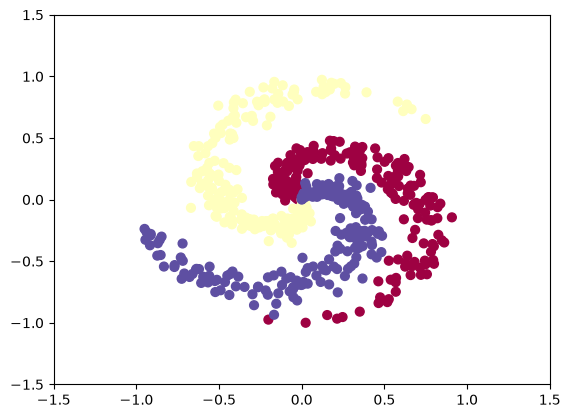

Final: (2000, 0.2730805277824402, 0.8979167342185974, 0.8666667342185974)


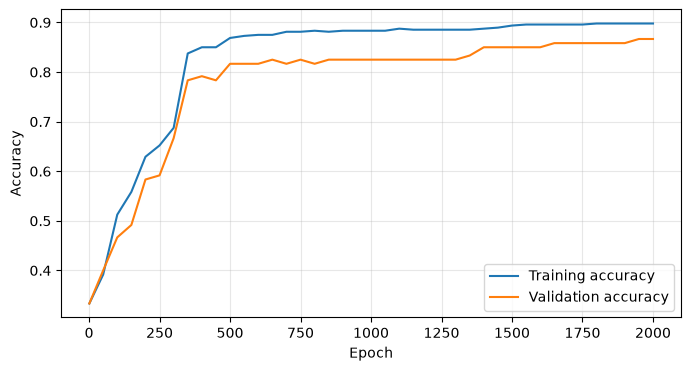

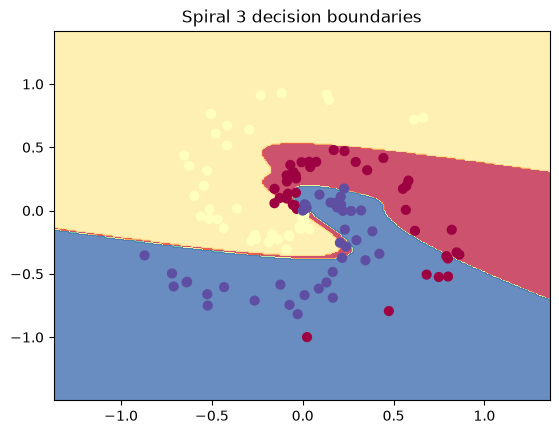

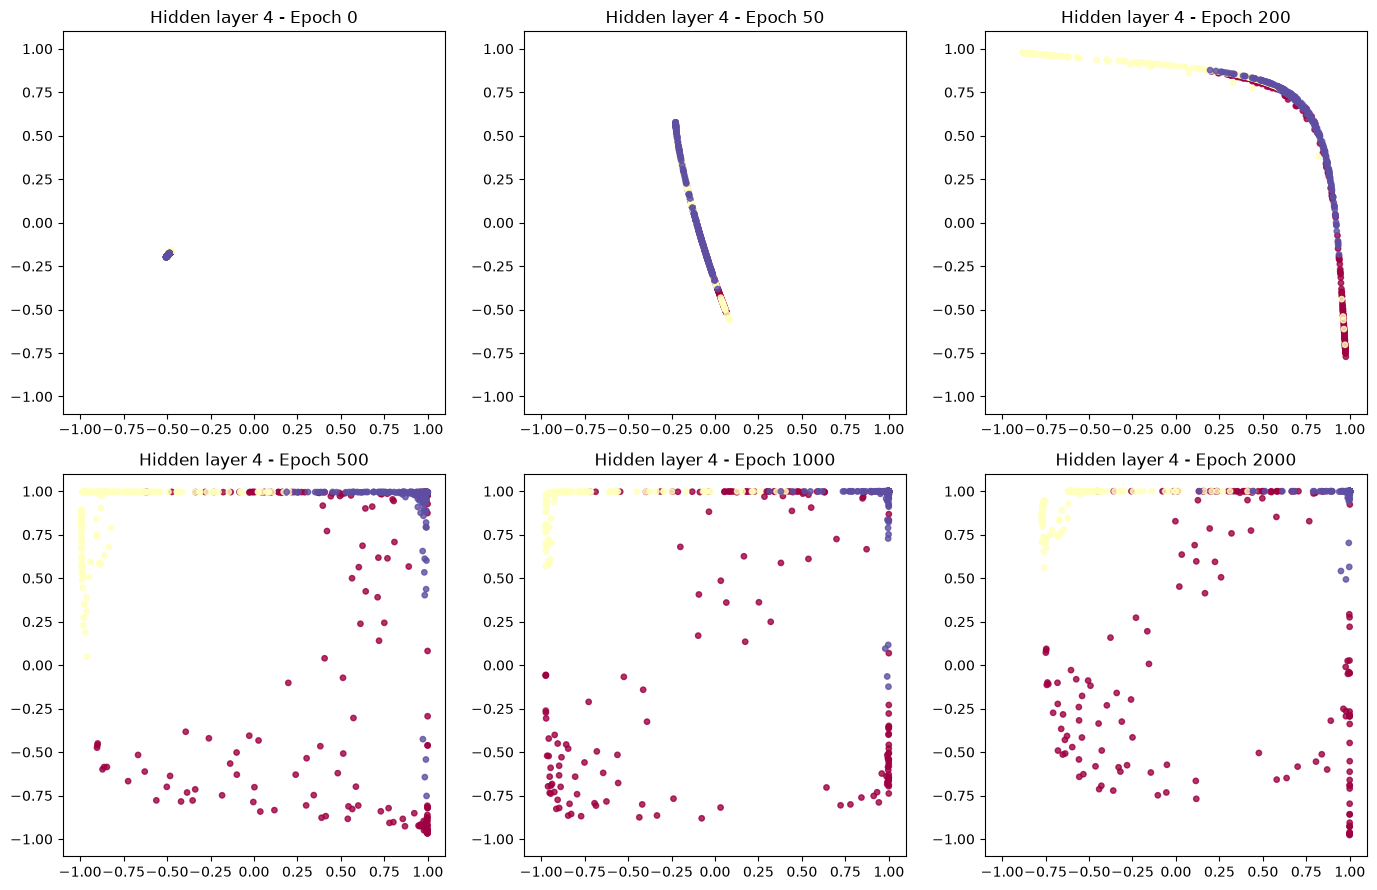

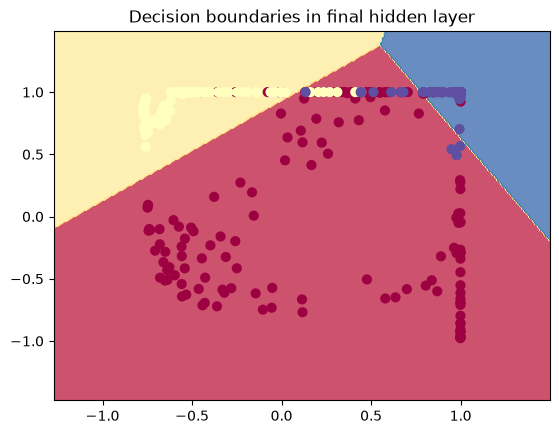

In [ ]:
# Experiment 1

def toy_spiral3(N=200, K=3, D=2):
    # N points per class, D dimensions, K classes, arranged as three interleaved arms
    np.random.seed(0)
    X = np.zeros((N * K, D))
    y = np.zeros(N * K, dtype='uint8')
    for j in range(K):
        ix = range(N * j, N * (j + 1))
        r = np.linspace(0.0, 1, N)                                    # radius
        t = 5 + np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.3   # angle
        X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
        y[ix] = j
    return X, y


def toy_plot(X, y):
    plt.figure()
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
    plt.xlim([-1.5, 1.5])
    plt.ylim([-1.5, 1.5])


def plot_decision_boundaries(X, y, f, title=""):
    h = 0.01
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = f(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure()
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title)
    plt.show()

# Generate spiral
X, y = toy_spiral3()
# 80/20 training-validation split
rng = np.random.default_rng(SEED)
train_idx, val_idx = [], []
for c in np.unique(y):
  indices = rng.permutation(np.flatnonzero(y == c))
  cut = int(0.8 * len(indices))
  train_idx.extend(indices[:cut])
  val_idx.extend(indices[cut:])
X_train = torch.tensor(X[train_idx], dtype=torch.float32, device=device)
y_train = torch.tensor(y[train_idx], dtype=torch.long, device=device)
X_val = torch.tensor(X[val_idx], dtype=torch.float32, device=device)
y_val = torch.tensor(y[val_idx], dtype=torch.long, device=device)
toy_plot(X, y)
plt.show()

class SpiralNet(nn.Module):
  def __init__(self, n_hidden=3):
    super().__init__()
    self.hidden = nn.ModuleList()
    for _ in range(n_hidden):
      self.hidden.append(nn.Sequential(nn.Linear(2, 2), nn.Tanh()))
    self.output = nn.Linear(2, 3)

  def project(self, x, layer_index):
    """
    layer_index = 0: original input
    layer_index = 1: first hidden layer
    layer_index = 2: second hidden layer
    etc.
    """
    if not 0 <= layer_index <= len(self.hidden):
      raise ValueError("Invalid layer index")
    for layer in self.hidden[:layer_index]:
      x = layer(x)
    return x

  def forward(self, x):
    x = self.project(x, len(self.hidden))
    return self.output(x)

# Model setup
N_HIDDEN = 4
EPOCHS = 2000
LEARNING_RATE = 0.01
WEIGHT_DECAY = 1e-5

CHECKPOINTS= [0, 50, 200, 500, 1000, 2000]
model = SpiralNet(n_hidden=N_HIDDEN).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# For history
def save_state(model):
  return {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}

states = {0: save_state(model)}
history = []
for epoch in range(1, EPOCHS + 1):
  model.train()
  optimizer.zero_grad()
  logits = model(X_train)
  loss = criterion(logits, y_train)
  loss.backward()
  optimizer.step()
  if epoch in CHECKPOINTS:
    states[epoch] = save_state(model)
  if epoch % 50 == 0 or epoch == 1:
    model.eval()
    with torch.no_grad():
      train_acc = ((model(X_train).argmax(dim=1) == y_train).float().mean().item())
      val_acc = ((model(X_val).argmax(dim=1) == y_val).float().mean().item())
    history.append((epoch, loss.item(), train_acc, val_acc))
print("Final:", history[-1])

# CHeck training performance
history_array = np.array(history)
plt.figure(figsize=(8,4))
plt.plot(history_array[:, 0], history_array[:, 2], label="Training accuracy")
plt.plot(history_array[:, 0], history_array[:, 3], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

def predict_classes(X_numpy):
  model.eval()
  with torch.no_grad():
    inputs = torch.tensor(X_numpy, dtype=torch.float32, device=device)
    logits = model(inputs)
    predictions = logits.argmax(dim=1)
  return predictions.cpu().numpy()

plot_decision_boundaries(X[val_idx], y[val_idx], predict_classes, title="Spiral 3 decision boundaries")

# Visualisation of a hidden layer
VIS_LAYER = 4 # 0 = input, 1..N_HIDDEN = hidden layers
X_all = torch.tensor(X, dtype=torch.float32, device=device)
view_model = SpiralNet(n_hidden=N_HIDDEN).to(device)
fig, axes = plt.subplots(2, 3, figsize=(14,9))
for ax, (epoch, weights) in zip(axes.flat, sorted(states.items())):
  view_model.load_state_dict(weights)
  view_model.eval()
  with torch.no_grad():
    projection = view_model.project(X_all, VIS_LAYER).cpu().numpy()
  ax.scatter(projection[:, 0], projection[:, 1], c=y, cmap=plt.cm.Spectral, vmin=0, vmax=2, s=15, alpha=0.8)
  ax.set_xlim(-1.1, 1.1)
  ax.set_ylim(-1.1, 1.1)
  ax.set_aspect("equal", adjustable="box")
  ax.set_title(f"Hidden layer {VIS_LAYER} - Epoch {epoch}")
plt.tight_layout()
plt.show()

model.eval()
with torch.no_grad():
  H = model.project(X_all, N_HIDDEN).cpu().numpy()

def predict_in_hidden_space(H_numpy):
  with torch.no_grad():
    h = torch.tensor(H_numpy, dtype=torch.float32, device=device)
    logits = model.output(h)
    return logits.argmax(dim=1).cpu().numpy()

plot_decision_boundaries(H, y, predict_in_hidden_space, title="Decision boundaries in final hidden layer")

# Expérience 1

En utilisant UMAP, nous pouvons observer l'évolution de la représentation apprise à chaque couche, et l'évolution de la dernière couche (ici, la quatrième) est particulièrement intéressante: on peut voir que la projection des points tend vers une représentation mieux linéairement séparable des points. En fonction de comment le modèle apprend, on peut même se retrouver avec une division 1/3 - 1/3 - 1/3 du plan pour chaque classe.

On utilise deux neurones par couche car cela produit une représentation qui est déjà en deux dimensions, et donc plus simple à visualiser. On aurait également pu utiliser UMAP si chaque couche possèdait plus de deux neurones, mais cette configuration facilite la visualisation.